# Distributed segmentation on SLURM

`run_distributed_segmentation` spreads a whole slide over many Dask workers —
CPU processes on one machine, or GPU jobs that SMINT submits to SLURM — and
then **stitches** the tiles back together, so cells on tile boundaries come
out whole and every nucleus belongs to exactly one cell.

In this tutorial you will:

1. run it with `backend="local"` (two CPU workers) on the synthetic image from
   [Segment a whole slide](../01_segmentation/);
2. read the stitching log and the output tables;
3. see the same call for SLURM GPU workers, with the numbers from a real run.

**Runtime:** about a minute on 8 CPU cores. **Requires:** SMINT with the
`distributed` extra (`dask.distributed`, `dask-jobqueue`, `zarr`, `shapely`)
and Cellpose 3 for the built-in `cyto3` / `nuclei` models.

**Download this notebook:** [04_distributed_segmentation.ipynb](04_distributed_segmentation.ipynb)

In [1]:
import logging
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
import zarr
from matplotlib.patches import Rectangle

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s",
                    stream=sys.stdout, force=True)
import os
import warnings
warnings.filterwarnings("ignore", module=r"(torch|cellpose)\.")   # library deprecation notices
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"             # ... in the worker processes too

from smint.segmentation import run_distributed_segmentation

# Keep SMINT's log; quieten Dask's own scheduler / worker messages and model loading
for noisy in ("cellpose", "distributed", "tornado", "bokeh"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

## How tiles are processed

The image is cut into a grid of **core tiles** (`chunk_size`). Each worker
segments its tile **expanded by `tile_overlap` pixels** on every side, so a
cell on a boundary is seen whole by both neighbouring tiles. The worker writes
only its core region into the shared label masks, but reports the outline of
every object in the expanded tile. The coordinator then:

1. **stitches nuclei** — duplicates from neighbouring tiles that overlap by more
   than `stitch_merge_thresh` (0.5) are merged; smaller overlaps are trimmed;
2. **drops cells that touch no nucleus**, then stitches cells the same way;
3. **reconciles** cells and nuclei so every nucleus sits in exactly one cell.

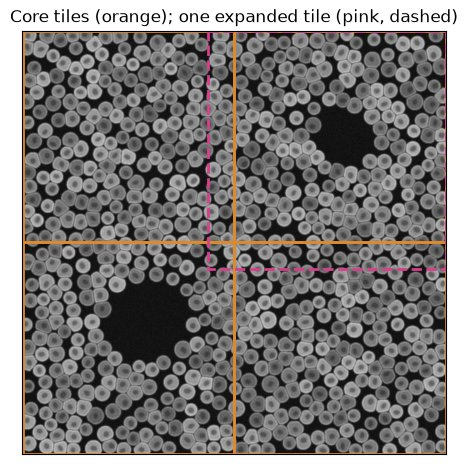

In [2]:
image = tifffile.imread("data/synthetic_wsi.ome.tif")
tile, overlap = 512, 64

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(image[1], cmap="gray")
for y in range(0, 1024, tile):
    for x in range(0, 1024, tile):
        ax.add_patch(Rectangle((x, y), tile, tile, fill=False, ec="#dd8a2e", lw=2))
x0, y0 = 512, 0   # the tile at top right, with its overlap margin
ax.add_patch(Rectangle((x0 - overlap, y0), tile + overlap, tile + overlap,
                       fill=False, ec="#d53f8c", lw=2, ls="--"))
ax.set_title("Core tiles (orange); one expanded tile (pink, dashed)")
ax.set_xticks([]); ax.set_yticks([])
plt.show()

`tile_overlap` must be larger than the biggest cell's radius. Here cells are
about 36 px across, so 64 px is plenty.

## 1. Run on local workers

Model parameters go in a dictionary per model, with the same keys as Cellpose:
`diameter`, `flow_threshold`, `cellprob_threshold` and `channels` (Cellpose 3
convention, `[main, nuclear]`, 1-based). `use_gpu=False` starts plain CPU
workers; on a machine with GPUs and `dask-cuda`, `use_gpu=True` starts one
worker per GPU.

In [3]:
results = run_distributed_segmentation(
    image_path="data/synthetic_wsi.ome.tif",
    output_dir="distributed_seg",
    cell_model="cyto3",
    nuclei_model="nuclei",
    cell_params={"diameter": 36, "flow_threshold": 0.4,
                 "cellprob_threshold": 0.0, "channels": [2, 1]},
    nuclei_params={"diameter": 15, "flow_threshold": 0.4,
                   "cellprob_threshold": 0.0, "channels": [1, 0]},
    chunk_size=512, tile_overlap=64,
    backend="local", n_workers=2, use_gpu=False,
)

INFO smint.distributed_seg: Image data/synthetic_wsi.ome.tif: 2 channel(s), 1024 x 1024 px


INFO smint.distributed_seg: Tiles: 4 of 512 px, 64 px overlap


INFO smint.distributed_seg: Cell model: cyto3 {'diameter': 36, 'flow_threshold': 0.4, 'cellprob_threshold': 0.0, 'channels': [2, 1]}


INFO smint.distributed_seg: Nuclei model: nuclei {'diameter': 15, 'flow_threshold': 0.4, 'cellprob_threshold': 0.0, 'channels': [1, 0]}


INFO smint.distributed_seg: Dask dashboard: http://127.0.0.1:8787/status


...

INFO smint.segmentation.stitching: Stitched 984 polygons: 753 after merging, 753 after trim/remove


INFO smint.segmentation.stitching: Reconciled 753 cells / 753 nuclei -> 753 cells / 753 nuclei


INFO smint.distributed_seg: 753 cells -> distributed_seg/cells_outlines.csv


INFO smint.distributed_seg: 753 nuclei -> distributed_seg/nuclei_outlines.csv


INFO smint.distributed_seg: Done in 1.2 min


Reading the log:

- **Tile k/4 (...): N cells, M nuclei** — each tile counts every object in its
  *expanded* region, so cells near a boundary are counted by two tiles.
- **Stitched P polygons: A after merging, B after trim/remove** — duplicates
  merged into one; overlapping leftovers trimmed or removed.
- **X of Y cell outlines touch no nucleus and were dropped.**
- **Reconciled ...** — the final cell and nucleus counts after every nucleus is
  assigned to one cell (a cell with no nucleus left is removed; a nucleus with
  no cell keeps its own outline as its cell).

In [4]:
summary = {k: results[k] for k in ("total_cells", "total_nuclei", "n_tiles", "failed_tiles")}
truth = pd.read_csv("data/synthetic_wsi_truth.csv")
print(summary, f"- the image holds {len(truth)} cells")

{'total_cells': 753, 'total_nuclei': 753, 'n_tiles': 4, 'failed_tiles': []} - the image holds 753 cells


## 2. The outputs

| File | Contents |
|---|---|
| `cells_outlines.csv`, `nuclei_outlines.csv` | One row per outline vertex: `global_cell_id`, `x`, `y` (IDs from 1, after stitching) |
| `cells_summary.csv` | One row per cell: `global_cell_id`, `x_centroid`, `y_centroid`, `area`, `n_nuclei` |
| `nuclei_summary.csv` | One row per nucleus, with `cell_id`: the `global_cell_id` of its cell |
| `cells.zarr`, `nuclei.zarr` | Full-resolution label masks, as written by the tiles (per-tile IDs, not the stitched ones) |
| `distributed_seg_<time>.log` | The log above |

In [5]:
cells = pd.read_csv(results["cells_summary_path"])
nuclei = pd.read_csv(results["nuclei_summary_path"])
print(cells["n_nuclei"].value_counts().sort_index().to_string())
cells.head()

n_nuclei
1    753


,global_cell_id,x_centroid,y_centroid,area,n_nuclei
0,1,16.419921,12.349659,806.5,1
1,2,59.466771,13.520389,960.5,1
2,3,121.016998,13.334879,755.0,1
3,4,152.494569,11.184649,690.5,1
4,5,201.387841,15.295248,954.0,1


In [6]:
nuclei.head()

,global_cell_id,x_centroid,y_centroid,area,cell_id
0,1,150.025641,9.043185,123.5,4
1,2,576.894425,8.916963,140.5,11
2,3,59.953887,9.552042,126.5,2
3,4,528.983479,12.283771,171.5,10
4,5,283.023580,12.294748,155.5,7


On this image the stitched result has exactly as many cells as the truth
table, each with one nucleus (`n_nuclei` above). The overlay shows the
stitched outlines; compare the tile boundary with the split cells in
[Segment a whole slide](../01_segmentation/).

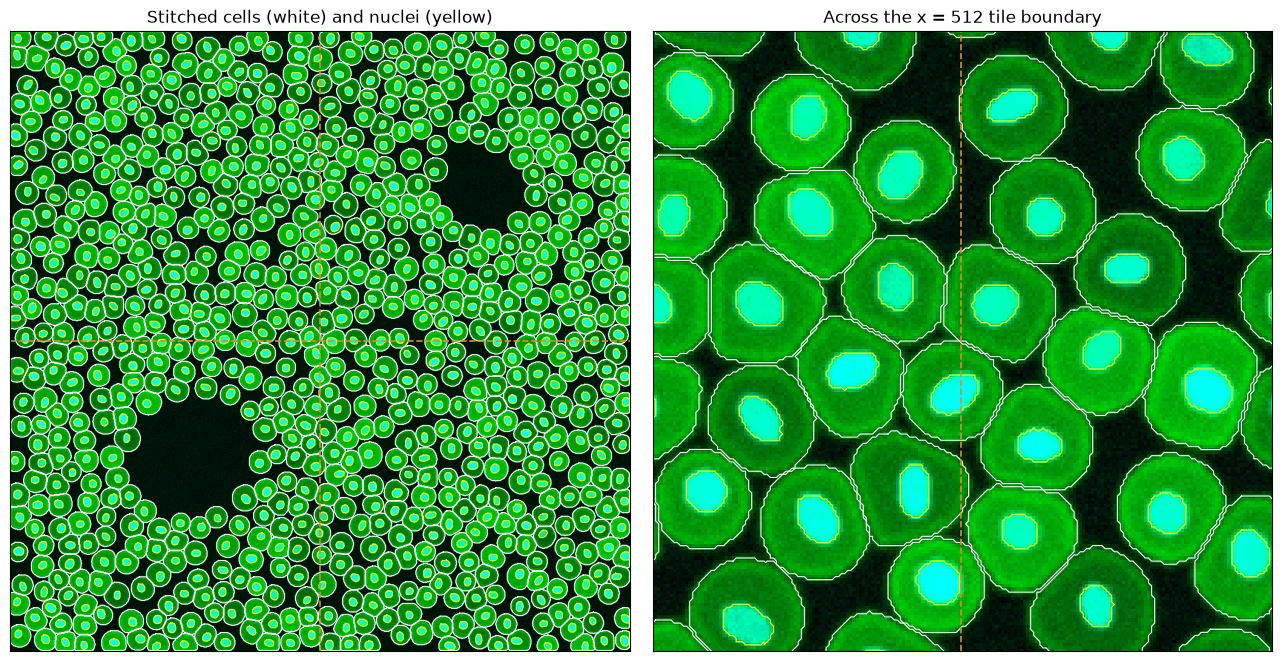

In [7]:
def composite(image, colours):
    rgb = np.zeros(image.shape[1:] + (3,))
    for channel, colour in zip(image, colours):
        lo, hi = np.percentile(channel, (1, 99.7))
        rgb += np.clip((channel - lo) / (hi - lo), 0, 1)[..., None] * np.asarray(colour)
    return np.clip(rgb, 0, 1)

cell_outlines = pd.read_csv(results["cells_csv_path"])
nuclei_outlines = pd.read_csv(results["nuclei_csv_path"])
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax in axes:
    ax.imshow(composite(image, [(0, 1, 1), (0, 0.8, 0)]))
    for outlines, colour in ((cell_outlines, "white"), (nuclei_outlines, "yellow")):
        for _, obj in outlines.groupby("global_cell_id"):
            ax.plot(obj.x, obj.y, color=colour, lw=0.8)
    ax.axvline(511.5, color="#dd8a2e", ls="--", lw=1.2); ax.axhline(511.5, color="#dd8a2e", ls="--", lw=1.2)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].set_title("Stitched cells (white) and nuclei (yellow)")
axes[1].set(xlim=(412, 612), ylim=(300, 100), title="Across the x = 512 tile boundary")
plt.tight_layout(); plt.show()

The label masks are Zarr arrays the size of the image, so you can read any
window without loading the whole slide:

In [8]:
masks = zarr.open_array(results["cells_zarr_path"], mode="r")
print(masks.shape, masks.dtype)
window = masks[0:300, 412:712]
print(f"{len(np.unique(window)) - 1} labels in a 300 x 300 px window")

(1024, 1024) uint32
89 labels in a 300 x 300 px window


## 3. On SLURM GPUs

For a real slide, give each worker a GPU. With `backend="slurm"`, SMINT starts
the workers as SLURM jobs through `dask-jobqueue`; `slurm` takes
`dask_jobqueue.SLURMCluster` options plus `gpu_type`, which adds
`--gres=gpu:<type>:1` to every worker job. The image and `output_dir` must be
on storage every node can read.

```python
from smint.segmentation import run_distributed_segmentation

results = run_distributed_segmentation(
    image_path="sample3_tile_scan.ome.tif",           # OME-TIFF or OME-Zarr, on shared storage
    output_dir="sample3_segmentation",                # on shared storage too
    cell_model="/path/to/models/cpsam_finetuned",     # a fine-tuned Cellpose-SAM model
    nuclei_model="nuclei",
    cell_params={"diameter": 120, "flow_threshold": 0.6,
                 "cellprob_threshold": -2.5, "channels": [2, 1]},
    nuclei_params={"diameter": 25, "flow_threshold": 0.3,
                   "cellprob_threshold": 0.2, "channels": [1, 0]},
    chunk_size=1048, tile_overlap=256,
    backend="slurm", n_workers=4,
    slurm={"queue": "gpuq", "gpu_type": "A30", "memory": "64GB"},
)
```

This is the call behind the measured run in the
[worked examples](../../examples/#5-distributed-segmentation-on-slurm-gpus): a
4096 × 4096 px Sample 3 tile scan, 16 tiles, 4 A30 workers, Cellpose 4 with a
fine-tuned model. It logged:

```text
Tiles: 16 of 1048 px, 256 px overlap
4 worker(s) ready
Stitched 66 polygons: 44 after merging, 44 after trim/remove
30 of 103 cell outlines touch no nucleus and were dropped
Stitched 73 polygons: 43 after merging, 43 after trim/remove
Reconciled 43 cells / 44 nuclei -> 44 cells / 44 nuclei
Done in 0.6 min
```

Run the coordinator itself as a small CPU job: it only submits the GPU
workers and stitches their results. For example, with the call above saved
as `segment.py`:

```bash
#!/bin/bash
#SBATCH --partition=regular
#SBATCH --cpus-per-task=2
#SBATCH --mem=16G
#SBATCH --time=04:00:00
python segment.py
```

## Next steps

- [Tiling and stitching](../../concepts/tiling_and_stitching/) — how merging,
  trimming and reconciliation decide.
- [Running on HPC](../../hpc_deployment/) — partitions, GPUs and monitoring.
- [Configuration](../../reference/configuration/) — the same settings in a YAML file.